## Creation des nouvelles variables pour rendre le dataset plus facile a exploiter par les models.

In [2]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder

In [4]:
data = pd.read_csv('AirQualityUCI_cleaned.csv')
data.head()

,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,DateTime
0,1.620511,1545.0,176.904406,22.1,1353.0,245.757321,767.0,112.291221,2058.0,1588.0,9.2,56.2,0.6561,2004-03-12 09:00:00
1,2.800000,1473.0,176.904406,14.3,1127.0,224.000000,831.0,152.000000,1752.0,1568.0,20.8,34.4,0.8365,2004-03-18 11:00:00
2,2.200000,1379.0,176.904406,12.5,1068.0,171.000000,899.0,139.000000,1663.0,1374.0,23.8,28.2,0.8219,2004-03-18 12:00:00
3,2.200000,1385.0,176.904406,12.2,1056.0,149.000000,891.0,133.000000,1648.0,1268.0,24.2,28.7,0.8515,2004-03-18 13:00:00
4,2.300000,1379.0,176.904406,13.1,1087.0,137.000000,901.0,126.000000,1660.0,1144.0,25.2,24.9,0.7829,2004-03-18 14:00:00


In [ ]:

def air_quality_feature_engineering(df):
    """
    Feature engineering complet pour le dataset AirQualityUCI
    
    Args:
        df: DataFrame avec les colonnes AirQualityUCI
        
    Returns:
        DataFrame avec les nouvelles features
    """
    # Copie pour éviter de modifier l'original
    df_fe = df.copy()
    
    # Conversion DateTime si nécessaire
    if 'DateTime' in df_fe.columns:
        df_fe['DateTime'] = pd.to_datetime(df_fe['DateTime'])
        df_fe = df_fe.sort_values('DateTime').reset_index(drop=True)
    
    print("🕐 Création des features temporelles...")
    # 1. Features temporelles
    if 'DateTime' in df_fe.columns:
        df_fe['Hour'] = df_fe['DateTime'].dt.hour
        df_fe['DayOfWeek'] = df_fe['DateTime'].dt.dayofweek
        df_fe['Month'] = df_fe['DateTime'].dt.month
        df_fe['Season'] = df_fe['Month'].map({12:0, 1:0, 2:0, 3:1, 4:1, 5:1, 
                                           6:2, 7:2, 8:2, 9:3, 10:3, 11:3})
        df_fe['IsWeekend'] = (df_fe['DayOfWeek'] >= 5).astype(int)
        df_fe['IsRushHour'] = ((df_fe['Hour'].between(7, 9)) | 
                              (df_fe['Hour'].between(17, 19))).astype(int)
        df_fe['IsNight'] = ((df_fe['Hour'] >= 22) | (df_fe['Hour'] <= 6)).astype(int)
        df_fe['DayOfYear'] = df_fe['DateTime'].dt.dayofyear
    
    print("🌡️ Création des features météorologiques...")
    # 2. Features météorologiques dérivées
    if all(col in df_fe.columns for col in ['T', 'RH', 'AH']):
        # Index de confort thermique approximatif
        df_fe['DiscomfortIndex'] = 0.5 * (df_fe['T'] + 61.0 + 
                                         ((df_fe['T'] - 68.0) * 1.2) + 
                                         (df_fe['RH'] * 0.094))
        
        # Ratios d'humidité
        df_fe['AH_RH_Ratio'] = df_fe['AH'] / (df_fe['RH'] + 1e-6)
        df_fe['Temp_Humidity_Product'] = df_fe['T'] * df_fe['RH']
        df_fe['Temp_Squared'] = df_fe['T'] ** 2
        df_fe['RH_Squared'] = df_fe['RH'] ** 2
    
    print("📊 Création des ratios capteurs/références...")
    # 3. Features de ratios capteurs/références
    sensor_ref_pairs = [
        ('PT08.S1(CO)', 'CO(GT)'),
        ('PT08.S2(NMHC)', 'NMHC(GT)'),
        ('PT08.S3(NOx)', 'NOx(GT)'),
        ('PT08.S4(NO2)', 'NO2(GT)')
    ]
    
    for sensor, reference in sensor_ref_pairs:
        if sensor in df_fe.columns and reference in df_fe.columns:
            df_fe[f'{sensor}_Accuracy'] = df_fe[sensor] / (df_fe[reference] + 1e-6)
            df_fe[f'{sensor}_Diff'] = df_fe[sensor] - df_fe[reference]
    
    print("🏭 Création des indices de pollution...")
    # 4. Indices de pollution composite
    pollution_cols = ['CO(GT)', 'NO2(GT)', 'C6H6(GT)', 'NOx(GT)']
    available_pollution_cols = [col for col in pollution_cols if col in df_fe.columns]
    
    if len(available_pollution_cols) >= 2:
        # Index de qualité de l'air simplifié
        if all(col in df_fe.columns for col in ['CO(GT)', 'NO2(GT)', 'C6H6(GT)', 'NOx(GT)']):
            df_fe['AQI_Simple'] = (df_fe['CO(GT)'] * 0.2 + df_fe['NO2(GT)'] * 0.3 + 
                                  df_fe['C6H6(GT)'] * 0.25 + df_fe['NOx(GT)'] * 0.25)
        
        # Pollution totale des oxydes d'azote
        if all(col in df_fe.columns for col in ['NOx(GT)', 'NO2(GT)']):
            df_fe['Total_NOx'] = df_fe['NOx(GT)'] + df_fe['NO2(GT)']
            df_fe['NO2_NOx_Ratio'] = df_fe['NO2(GT)'] / (df_fe['NOx(GT)'] + 1e-6)
        
        # Somme totale des polluants principaux
        df_fe['Total_Pollution'] = df_fe[available_pollution_cols].sum(axis=1)
    
    print("📈 Création des moyennes mobiles...")
    # 5. Features de moyennes mobiles
    ma_cols = ['CO(GT)', 'NO2(GT)', 'C6H6(GT)', 'T', 'RH']
    available_ma_cols = [col for col in ma_cols if col in df_fe.columns]
    
    for col in available_ma_cols:
        # Moyennes mobiles
        df_fe[f'{col}_MA_3h'] = df_fe[col].rolling(window=3, center=True, min_periods=1).mean()
        df_fe[f'{col}_MA_6h'] = df_fe[col].rolling(window=6, center=True, min_periods=1).mean()
        df_fe[f'{col}_MA_24h'] = df_fe[col].rolling(window=24, center=True, min_periods=1).mean()
        
        # Tendances
        df_fe[f'{col}_Trend_3h'] = df_fe[col] - df_fe[f'{col}_MA_3h']
        df_fe[f'{col}_Trend_24h'] = df_fe[col] - df_fe[f'{col}_MA_24h']
    
    print("📊 Création des features de variabilité...")
    # 6. Features de variabilité
    volatility_cols = ['CO(GT)', 'NO2(GT)', 'C6H6(GT)']
    available_vol_cols = [col for col in volatility_cols if col in df_fe.columns]
    
    for col in available_vol_cols:
        # Écarts-types mobiles
        df_fe[f'{col}_Std_6h'] = df_fe[col].rolling(window=6, min_periods=1).std()
        df_fe[f'{col}_Std_24h'] = df_fe[col].rolling(window=24, min_periods=1).std()
        
        # Volatilité relative
        if f'{col}_MA_6h' in df_fe.columns:
            df_fe[f'{col}_Volatility'] = df_fe[f'{col}_Std_6h'] / (df_fe[f'{col}_MA_6h'] + 1e-6)
    
    print("⏰ Création des features de retards...")
    # 7. Features de retards (lag features)
    lag_cols = ['CO(GT)', 'NO2(GT)', 'T', 'RH']
    available_lag_cols = [col for col in lag_cols if col in df_fe.columns]
    
    for col in available_lag_cols:
        # Valeurs retardées
        df_fe[f'{col}_Lag1h'] = df_fe[col].shift(1)
        df_fe[f'{col}_Lag3h'] = df_fe[col].shift(3)
        df_fe[f'{col}_Lag6h'] = df_fe[col].shift(6)
        
        # Changements
        df_fe[f'{col}_Change1h'] = df_fe[col] - df_fe[f'{col}_Lag1h']
        df_fe[f'{col}_Change3h'] = df_fe[col] - df_fe[f'{col}_Lag3h']
        
        # Taux de changement
        df_fe[f'{col}_Rate1h'] = df_fe[f'{col}_Change1h'] / (df_fe[f'{col}_Lag1h'] + 1e-6)
    
    print("🤝 Création des features d'interaction...")
    # 8. Features d'interaction environnementales
    if all(col in df_fe.columns for col in ['CO(GT)', 'T']):
        df_fe['CO_Temp_Interaction'] = df_fe['CO(GT)'] * df_fe['T']
    
    if all(col in df_fe.columns for col in ['NO2(GT)', 'RH']):
        df_fe['Pollution_Humidity_Effect'] = df_fe['NO2(GT)'] * df_fe['RH'] / 100
    
    if all(col in df_fe.columns for col in ['C6H6(GT)', 'T', 'RH']):
        df_fe['Benzene_Weather_Index'] = df_fe['C6H6(GT)'] / (df_fe['T'] * df_fe['RH'] + 1e-6)
    
    # Interactions entre polluants
    if all(col in df_fe.columns for col in ['CO(GT)', 'NO2(GT)']):
        df_fe['CO_NO2_Product'] = df_fe['CO(GT)'] * df_fe['NO2(GT)']
        df_fe['CO_NO2_Ratio'] = df_fe['CO(GT)'] / (df_fe['NO2(GT)'] + 1e-6)
    
    print("📊 Création des catégories...")
    # 9. Catégorisation des conditions
    if 'T' in df_fe.columns:
        df_fe['Temp_Category'] = pd.cut(df_fe['T'], 
                                       bins=[-np.inf, 5, 15, 25, np.inf], 
                                       labels=['Cold', 'Cool', 'Warm', 'Hot'])
        
        # Encodage des catégories
        le_temp = LabelEncoder()
        df_fe['Temp_Category_Encoded'] = le_temp.fit_transform(df_fe['Temp_Category'].astype(str))
    
    if 'RH' in df_fe.columns:
        df_fe['Humidity_Level'] = pd.cut(df_fe['RH'], 
                                        bins=[0, 30, 60, 80, 100], 
                                        labels=['Low', 'Medium', 'High', 'Very_High'])
        
        le_hum = LabelEncoder()
        df_fe['Humidity_Level_Encoded'] = le_hum.fit_transform(df_fe['Humidity_Level'].astype(str))
    
    if 'CO(GT)' in df_fe.columns:
        df_fe['CO_Level'] = pd.cut(df_fe['CO(GT)'], 
                                  bins=[-np.inf, df_fe['CO(GT)'].quantile(0.33), 
                                        df_fe['CO(GT)'].quantile(0.66), np.inf], 
                                  labels=['Low', 'Medium', 'High'])
        
        le_co = LabelEncoder()
        df_fe['CO_Level_Encoded'] = le_co.fit_transform(df_fe['CO_Level'].astype(str))
    
    print("🚨 Création des features de pics et anomalies...")
    # 10. Features de pics et anomalies
    peak_cols = ['CO(GT)', 'NO2(GT)', 'C6H6(GT)']
    available_peak_cols = [col for col in peak_cols if col in df_fe.columns]
    
    for col in available_peak_cols:
        # Pics de pollution (95e percentile)
        threshold_95 = df_fe[col].quantile(0.95)
        threshold_90 = df_fe[col].quantile(0.90)
        
        df_fe[f'{col}_Peak_95'] = (df_fe[col] > threshold_95).astype(int)
        df_fe[f'{col}_Peak_90'] = (df_fe[col] > threshold_90).astype(int)
        
        # Valeurs faibles (10e percentile)
        threshold_10 = df_fe[col].quantile(0.10)
        df_fe[f'{col}_Low_10'] = (df_fe[col] < threshold_10).astype(int)
    
    # Pic multi-polluants
    if len(available_peak_cols) >= 2:
        peak_columns = [f'{col}_Peak_95' for col in available_peak_cols]
        df_fe['Multi_Pollutant_Peak'] = df_fe[peak_columns].sum(axis=1)
    
    print("🧮 Création des features statistiques...")
    # 11. Features statistiques avancées
    if len(available_pollution_cols) >= 2:
        # Variance entre polluants
        df_fe['Pollution_Variance'] = df_fe[available_pollution_cols].var(axis=1)
        df_fe['Pollution_Std'] = df_fe[available_pollution_cols].std(axis=1)
        df_fe['Pollution_CV'] = df_fe['Pollution_Std'] / (df_fe['Total_Pollution'] + 1e-6)
    
    # Ratios min/max
    if 'T' in df_fe.columns:
        df_fe['T_Min_Max_Ratio'] = df_fe['T'] / (df_fe['T'].rolling(24, min_periods=1).max() + 1e-6)
    
    print("✅ Feature engineering terminé !")
    print(f"Nombre de features créées: {len(df_fe.columns) - len(df.columns)}")
    print(f"Nombre total de colonnes: {len(df_fe.columns)}")
    
    return df_fe

# Fonction utilitaire pour afficher un résumé des nouvelles features
def summarize_new_features(df_original, df_engineered):
    """
    Affiche un résumé des nouvelles features créées
    """
    original_cols = set(df_original.columns)
    new_cols = set(df_engineered.columns) - original_cols
    
    print(f"\n📊 RÉSUMÉ DES NOUVELLES FEATURES ({len(new_cols)} créées)")
    print("=" * 60)
    
    categories = {
        'Temporelles': [col for col in new_cols if any(x in col for x in ['Hour', 'Day', 'Month', 'Season', 'Weekend', 'Rush', 'Night'])],
        'Météorologiques': [col for col in new_cols if any(x in col for x in ['Temp', 'Humidity', 'Discomfort', 'AH_RH'])],
        'Ratios capteurs': [col for col in new_cols if 'Accuracy' in col or 'Diff' in col],
        'Indices pollution': [col for col in new_cols if any(x in col for x in ['AQI', 'Total', 'NOx_Ratio'])],
        'Moyennes mobiles': [col for col in new_cols if 'MA_' in col or 'Trend' in col],
        'Variabilité': [col for col in new_cols if any(x in col for x in ['Std', 'Volatility'])],
        'Retards': [col for col in new_cols if any(x in col for x in ['Lag', 'Change', 'Rate'])],
        'Interactions': [col for col in new_cols if 'Interaction' in col or 'Product' in col or 'Effect' in col or 'Index' in col],
        'Catégories': [col for col in new_cols if any(x in col for x in ['Category', 'Level', 'Encoded'])],
        'Pics/Anomalies': [col for col in new_cols if any(x in col for x in ['Peak', 'Low', 'Multi'])],
        'Statistiques': [col for col in new_cols if any(x in col for x in ['Variance', 'CV', 'Min_Max'])]
    }
    
    for category, cols in categories.items():
        if cols:
            print(f"\n{category}: {len(cols)} features")
            for col in sorted(cols)[:5]:  # Afficher les 5 premières
                print(f"  • {col}")
            if len(cols) > 5:
                print(f"  ... et {len(cols) - 5} autres")
    
    return new_cols


In [5]:
new_features = air_quality_feature_engineering(data)

🕐 Création des features temporelles...
🌡️ Création des features météorologiques...
📊 Création des ratios capteurs/références...
🏭 Création des indices de pollution...
📈 Création des moyennes mobiles...
📊 Création des features de variabilité...
⏰ Création des features de retards...
🤝 Création des features d'interaction...
📊 Création des catégories...
🚨 Création des features de pics et anomalies...
🧮 Création des features statistiques...
✅ Feature engineering terminé !
Nombre de features créées: 108
Nombre total de colonnes: 122


C:\Users\0000\AppData\Local\Temp\ipykernel_17768\3997570769.py:186: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_fe[f'{col}_Peak_90'] = (df_fe[col] > threshold_90).astype(int)
C:\Users\0000\AppData\Local\Temp\ipykernel_17768\3997570769.py:190: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_fe[f'{col}_Low_10'] = (df_fe[col] < threshold_10).astype(int)
C:\Users\0000\AppData\Local\Temp\ipykernel_17768\3997570769.py:195: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` m

In [6]:
new_features

,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),...,NO2(GT)_Peak_90,NO2(GT)_Low_10,C6H6(GT)_Peak_95,C6H6(GT)_Peak_90,C6H6(GT)_Low_10,Multi_Pollutant_Peak,Pollution_Variance,Pollution_Std,Pollution_CV,T_Min_Max_Ratio
0,1.620511,1545.0,176.904406,22.1,1353.0,245.757321,767.0,112.291221,2058.0,1588.0,...,0,0,1,1,0,1,12353.370852,111.145719,0.291133,1.000000
1,2.800000,1473.0,176.904406,14.3,1127.0,224.000000,831.0,152.000000,1752.0,1568.0,...,1,0,0,0,0,0,11620.142500,107.796765,0.274222,1.000000
2,2.200000,1379.0,176.904406,12.5,1068.0,171.000000,899.0,139.000000,1663.0,1374.0,...,0,0,0,0,0,0,7455.189167,86.343437,0.265918,1.000000
3,2.200000,1385.0,176.904406,12.2,1056.0,149.000000,891.0,133.000000,1648.0,1268.0,...,0,0,0,0,0,0,6026.813333,77.632553,0.261918,1.000000
4,2.300000,1379.0,176.904406,13.1,1087.0,137.000000,901.0,126.000000,1660.0,1144.0,...,0,0,0,0,0,0,5148.420000,71.752491,0.257732,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6790,1.100000,1031.0,176.904406,4.4,730.0,182.000000,760.0,93.000000,1129.0,905.0,...,0,0,0,0,0,0,7374.502500,85.874924,0.306149,0.316667
6791,2.400000,1163.0,176.904406,11.4,1027.0,353.000000,604.0,179.000000,1264.0,1269.0,...,1,0,0,0,0,1,27437.103333,165.641490,0.303484,0.810000
6792,2.400000,1142.0,176.904406,12.4,1063.0,293.000000,603.0,175.000000,1241.0,1092.0,...,1,0,0,0,0,1,19453.186667,139.474681,0.288887,0.896667
6793,2.100000,1003.0,176.904406,9.5,961.0,235.000000,702.0,156.000000,1041.0,770.0,...,1,0,0,0,0,0,13044.656667,114.213207,0.283689,0.943333


In [7]:
new_features.isnull().sum().sort_values(ascending=False)

T_Lag6h                  6
RH_Lag6h                 6
NO2(GT)_Lag6h            6
CO(GT)_Lag6h             6
RH_Lag3h                 3
                        ..
Total_NOx                0
AQI_Simple               0
PT08.S4(NO2)_Diff        0
PT08.S4(NO2)_Accuracy    0
T_Min_Max_Ratio          0
Length: 122, dtype: int64

In [8]:
new_features.dropna(inplace=True)

In [9]:
new_features.isnull().sum().sort_values(ascending=False)

CO(GT)                   0
RH_Lag1h                 0
T_Change3h               0
T_Change1h               0
T_Lag6h                  0
                        ..
Total_NOx                0
AQI_Simple               0
PT08.S4(NO2)_Diff        0
PT08.S4(NO2)_Accuracy    0
T_Min_Max_Ratio          0
Length: 122, dtype: int64

In [11]:
new_features.describe()

,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),...,NO2(GT)_Peak_90,NO2(GT)_Low_10,C6H6(GT)_Peak_95,C6H6(GT)_Peak_90,C6H6(GT)_Low_10,Multi_Pollutant_Peak,Pollution_Variance,Pollution_Std,Pollution_CV,T_Min_Max_Ratio
count,6789.000000,6789.000000,6.789000e+03,6789.000000,6789.000000,6789.000000,6789.000000,6789.000000,6789.000000,6789.000000,...,6789.000000,6789.000000,6789.000000,6789.000000,6789.000000,6789.000000,6789.000000,6789.000000,6789.000000,6789.000000
mean,1.671484,1043.481070,1.769044e+02,8.317053,884.392005,196.620329,843.516684,103.939488,1413.499687,928.466994,...,0.096921,0.097363,0.049934,0.098984,0.095154,0.143762,11079.838404,94.207324,0.294601,0.734115
min,0.100000,667.000000,1.769044e+02,0.500000,440.000000,14.000000,434.000000,23.000000,601.000000,288.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,111.172358,10.543830,0.219808,-0.463415
25%,1.100000,926.000000,1.769044e+02,4.300000,728.000000,108.000000,713.000000,82.000000,1199.000000,717.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3128.250000,55.930761,0.268604,0.614786
50%,1.620511,1031.000000,1.769044e+02,7.500000,876.000000,205.000000,834.000000,112.291221,1455.453452,914.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9514.590000,97.542760,0.294269,0.740458
75%,2.000000,1136.000000,1.769044e+02,11.100000,1017.000000,245.757321,955.000000,119.000000,1629.000000,1110.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,13378.464838,115.665314,0.315183,0.897436
max,4.700000,1573.000000,1.769044e+02,24.600000,1419.000000,502.000000,1361.000000,183.000000,2268.000000,1714.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,3.000000,55369.569167,235.307393,0.393708,1.000000
std,0.798578,154.106838,2.231269e-11,5.007034,201.306094,105.865049,181.599010,32.159036,308.708448,281.572262,...,0.295873,0.296474,0.217824,0.298662,0.293449,0.456681,10451.898560,46.958953,0.028212,0.197307


In [12]:
# save the engineered DataFrame
new_features.to_csv('AirQualityUCI_engineered.csv', index=False)

## Features selection
### Probleme de regression: Prédiction de concentrations du CO dans l'air 

### Feature selection basee sur les correlations


Top 20 features sélectionnées :
Index(['PT08.S1(CO)', 'NOx(GT)', 'NO2(GT)', 'PT08.S1(CO)_Accuracy',
       'PT08.S3(NOx)_Accuracy', 'CO(GT)_MA_3h', 'CO(GT)_MA_24h',
       'CO(GT)_Trend_3h', 'CO(GT)_Trend_24h', 'CO(GT)_Std_6h',
       'CO(GT)_Std_24h', 'CO(GT)_Volatility', 'CO(GT)_Lag3h',
       'CO(GT)_Change1h', 'CO(GT)_Change3h', 'CO(GT)_Rate1h',
       'CO_Temp_Interaction', 'Benzene_Weather_Index', 'CO_NO2_Ratio',
       'CO_Level_Encoded'],
      dtype='object')


<Figure size 1000x600 with 0 Axes>

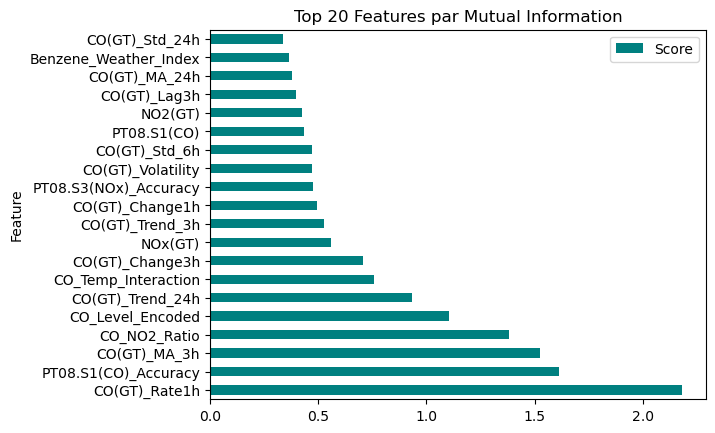

In [50]:
# Après votre code existant...
from sklearn.feature_selection import SelectKBest, mutual_info_regression

# 1. D'abord supprimer les features corrélées (comme vous le faites déjà)
X_filtered = remove_correlated_features(X, threshold=0.8) 

# 2. Ensuite sélectionner les 20 meilleures features avec SelectKBest
selector = SelectKBest(score_func=mutual_info_regression, k=20)
X_selected = selector.fit_transform(X_filtered, y)

# Récupérer les noms des colonnes sélectionnées
selected_features = X_filtered.columns[selector.get_support()]
print("\nTop 20 features sélectionnées :")
print(selected_features)

# 3. Visualisation des scores
plt.figure(figsize=(10, 6))
scores = pd.DataFrame({
    'Feature': X_filtered.columns,
    'Score': selector.scores_
}).sort_values('Score', ascending=False)

# Afficher les 20 meilleures
scores.head(20).plot.barh(x='Feature', y='Score', color='teal')
plt.title("Top 20 Features par Mutual Information")
plt.show()

In [51]:
X_filtered.to_csv('data_x_selection/AirQualityUCI_filtered_features.csv', index=False)

In [16]:
X_filtered.shape, y.shape

((6789, 66), (6789,))

In [52]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import mutual_info_regression

# 2. Suppression des features corrélées (>80%)
def remove_correlated_features(df, threshold=0.8):
    corr_matrix = df.corr().abs()
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    to_drop = [col for col in upper.columns if any(upper[col] > threshold)]
    return df.drop(to_drop, axis=1)

X_filtered = remove_correlated_features(X)

# 3. Sélection des 20 meilleures features avec Mutual Information
selector = mutual_info_regression(X_filtered, y, random_state=42)
top20_idx = np.argsort(selector)[-20:]  # Indices des 20 meilleures
selected_features = X_filtered.columns[top20_idx]

# 4. Création du nouveau dataset
final_data = pd.concat([
    data[selected_features],
    data['CO(GT)']  # On conserve la target
], axis=1)

# 5. Sauvegarde
final_data.to_csv('data_x_selection/AirQualityUCI_top20features.csv', index=False)
print("Dataset sauvegardé avec les 20 meilleures features :")
print(selected_features)

Dataset sauvegardé avec les 20 meilleures features :
Index(['CO(GT)_Std_24h', 'Benzene_Weather_Index', 'CO(GT)_MA_24h',
       'CO(GT)_Lag3h', 'NO2(GT)', 'PT08.S1(CO)', 'CO(GT)_Volatility',
       'CO(GT)_Std_6h', 'PT08.S3(NOx)_Accuracy', 'CO(GT)_Change1h',
       'CO(GT)_Trend_3h', 'NOx(GT)', 'CO(GT)_Change3h', 'CO_Temp_Interaction',
       'CO(GT)_Trend_24h', 'CO_Level_Encoded', 'CO_NO2_Ratio', 'CO(GT)_MA_3h',
       'PT08.S1(CO)_Accuracy', 'CO(GT)_Rate1h'],
      dtype='object')


### Feature selection basee sur le test d'ANOVA

c:\Users\0000\anaconda3\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:113: RuntimeWarning: divide by zero encountered in divide
  f = msb / msw


Scores ANOVA des features sélectionnées :
                   Feature  ANOVA Score
10        CO_Level_Encoded          inf
11          CO(GT)_Peak_95          inf
12          CO(GT)_Peak_90          inf
13           CO(GT)_Low_10          inf
2     PT08.S1(CO)_Accuracy  5474.484211
5             CO(GT)_MA_3h  1295.753727
9           CO_NO2_Product   913.019507
7         CO(GT)_Trend_24h   508.969641
6             CO(GT)_MA_6h   412.306529
14    Multi_Pollutant_Peak   276.104970
0                 C6H6(GT)   201.473371
1            PT08.S2(NMHC)   201.395963
3   PT08.S2(NMHC)_Accuracy   201.395963
4       PT08.S2(NMHC)_Diff   201.395963
8             CO(GT)_Lag1h   199.837647


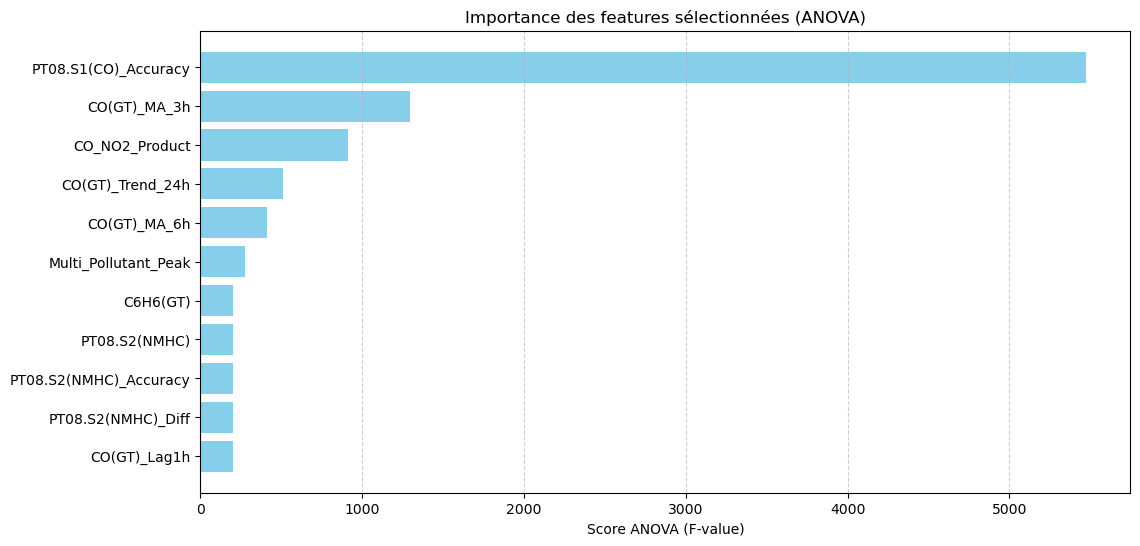

In [20]:
from sklearn.feature_selection import SelectKBest, f_classif
import matplotlib.pyplot as plt
import pandas as pd

# Sélection des k meilleures features avec ANOVA
selector = SelectKBest(score_func=f_classif, k=15)  # Choisir k features
X_new = selector.fit_transform(X, y)

# Récupérer les scores et noms des features
scores = selector.scores_
features = X.columns
selected_mask = selector.get_support()
selected_features = features[selected_mask]
selected_scores = scores[selected_mask]

# Créer un DataFrame pour les résultats
results_df = pd.DataFrame({
    'Feature': selected_features,
    'ANOVA Score': selected_scores
}).sort_values('ANOVA Score', ascending=False)

# Afficher les résultats
print("Scores ANOVA des features sélectionnées :")
print(results_df)

# Visualisation avec barplot
plt.figure(figsize=(12, 6))
plt.barh(results_df['Feature'], results_df['ANOVA Score'], color='skyblue')
plt.xlabel('Score ANOVA (F-value)')
plt.title('Importance des features sélectionnées (ANOVA)')
plt.gca().invert_yaxis()  # Afficher la feature la plus importante en haut
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.show()

D'Apres ce test d'ANOVA on peut prendre les 06 meilleures features

In [21]:
#save les résultats
results_df.to_csv('data_x_selection/AirQualityUCI_anova_scores.csv', index=False)

                  Feature  Importance
102      CO_Level_Encoded    0.622670
25   PT08.S1(CO)_Accuracy    0.175677
104        CO(GT)_Peak_90    0.145377
103        CO(GT)_Peak_95    0.016781
105         CO(GT)_Low_10    0.014552
0             PT08.S1(CO)    0.006270
26       PT08.S1(CO)_Diff    0.005985
41       CO(GT)_Trend_24h    0.005296
37           CO(GT)_MA_3h    0.002080
39          CO(GT)_MA_24h    0.001474


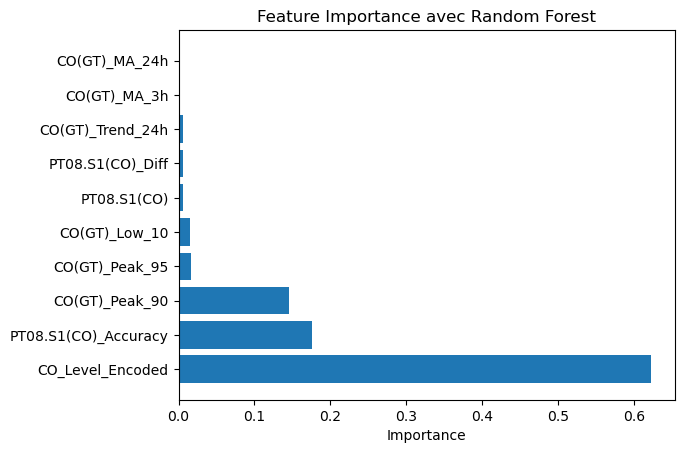

In [32]:
from sklearn.ensemble import RandomForestRegressor

# Entraîner un modèle Random Forest
model = RandomForestRegressor()
model.fit(X, y)

# Extraire l'importance des features
importance = model.feature_importances_
feature_importance = pd.DataFrame({'Feature': X.columns, 'Importance': importance})
feature_importance = feature_importance.sort_values('Importance', ascending=False).head(10)

# Afficher les features les plus importantes
print(feature_importance)

# Visualisation
plt.barh(feature_importance['Feature'], feature_importance['Importance'])
plt.xlabel('Importance')
plt.title('Feature Importance avec Random Forest')
plt.show()

Avec cette option nous pouvons prendre au max 05 features sion meme 03

### Model training

In [33]:
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.feature_selection import SelectFromModel
from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_squared_error

In [39]:
# !pip install xgboost

### Base learning without spliting data


Lasso - Features sélectionnées (117):
Index(['PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)',
       'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T',
       ...
       'NO2(GT)_Peak_90', 'NO2(GT)_Low_10', 'C6H6(GT)_Peak_95',
       'C6H6(GT)_Peak_90', 'C6H6(GT)_Low_10', 'Multi_Pollutant_Peak',
       'Pollution_Variance', 'Pollution_Std', 'Pollution_CV',
       'T_Min_Max_Ratio'],
      dtype='object', length=117)


c:\Users\0000\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.436e+01, tolerance: 3.522e-01
  model = cd_fast.enet_coordinate_descent(



ElasticNet - Features sélectionnées (117):
Index(['PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)',
       'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T',
       ...
       'NO2(GT)_Peak_90', 'NO2(GT)_Low_10', 'C6H6(GT)_Peak_95',
       'C6H6(GT)_Peak_90', 'C6H6(GT)_Low_10', 'Multi_Pollutant_Peak',
       'Pollution_Variance', 'Pollution_Std', 'Pollution_CV',
       'T_Min_Max_Ratio'],
      dtype='object', length=117)


c:\Users\0000\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.031e+01, tolerance: 3.311e-01
  model = cd_fast.enet_coordinate_descent(
c:\Users\0000\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.361e-01, tolerance: 3.641e-01
  model = cd_fast.enet_coordinate_descent(



Performance des modèles:
           RMSE_mean   RMSE_std
Ridge       5.213244  10.424873
Lasso       0.169023     0.0137
ElasticNet  0.165993   0.014325


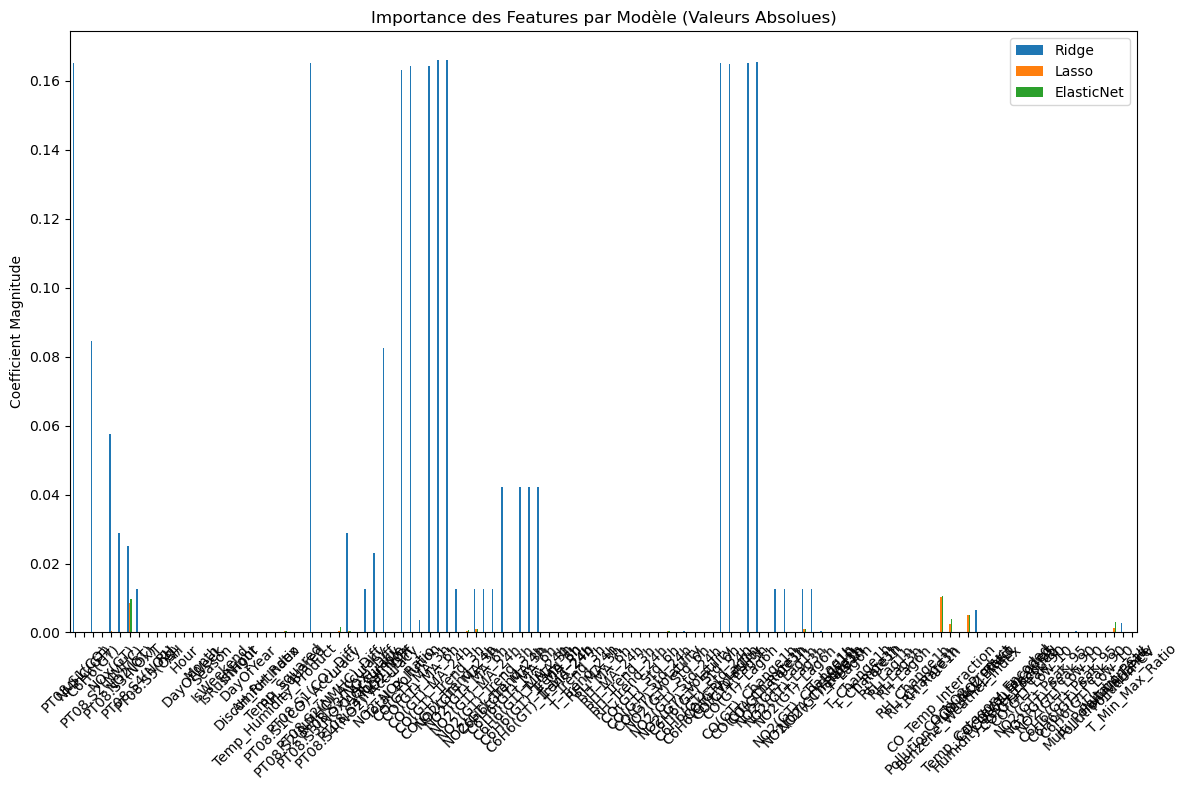

In [43]:
# 1. Définition des modèles avec paramètres optimisés
models = {
    'Ridge': Ridge(alpha=1.0),
    'Lasso': Lasso(alpha=0.1),  # Alpha plus bas pour plus de sélectivité
    'ElasticNet': ElasticNet(alpha=0.1, l1_ratio=0.7)  # Mix L1/L2
}

# 2. Entraînement et évaluation
results = {}
feature_importances = pd.DataFrame(index=X.columns)

for name, model in models.items():
    # Feature selection automatique (sauf pour Ridge)
    if name != 'Ridge':
        selector = SelectFromModel(model, threshold='median').fit(X, y)
        X_selected = selector.transform(X)
        selected_features = X.columns[selector.get_support()]
        print(f"\n{name} - Features sélectionnées ({len(selected_features)}):")
        print(selected_features)
    else:
        X_selected = X
    
    # Entraînement et validation croisée
    model.fit(X_selected, y)
    scores = cross_val_score(model, X_selected, y, cv=5, scoring='neg_mean_squared_error')
    rmse_scores = np.sqrt(-scores)
    
    # Stockage des résultats
    results[name] = {
        'RMSE_mean': rmse_scores.mean(),
        'RMSE_std': rmse_scores.std(),
        'model': model,
        'features': X_selected.columns if name == 'Ridge' else selected_features
    }
    
    # Récupération des coefficients
    if hasattr(model, 'coef_'):
        feature_importances[name] = np.abs(model.coef_)

# 3. Affichage des performances
results_df = pd.DataFrame(results).T
print("\nPerformance des modèles:")
print(results_df[['RMSE_mean', 'RMSE_std']])

# 4. Visualisation des coefficients
plt.figure(figsize=(12, 8))
feature_importances.plot(kind='bar', ax=plt.gca())
plt.title('Importance des Features par Modèle (Valeurs Absolues)')
plt.ylabel('Coefficient Magnitude')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

c:\Users\0000\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.436e+01, tolerance: 3.522e-01
  model = cd_fast.enet_coordinate_descent(
c:\Users\0000\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.031e+01, tolerance: 3.311e-01
  model = cd_fast.enet_coordinate_descent(
c:\Users\0000\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.361e-01, tolerance: 


Comparaison des modèles:
                  RMSE_mean   RMSE_std
XGBoost            0.057415   0.007364
GradientBoosting   0.058573   0.008605
RandomForest       0.089783   0.013177
ElasticNet         0.165993   0.014325
Lasso              0.169023   0.013700
Ridge              5.213244  10.424873


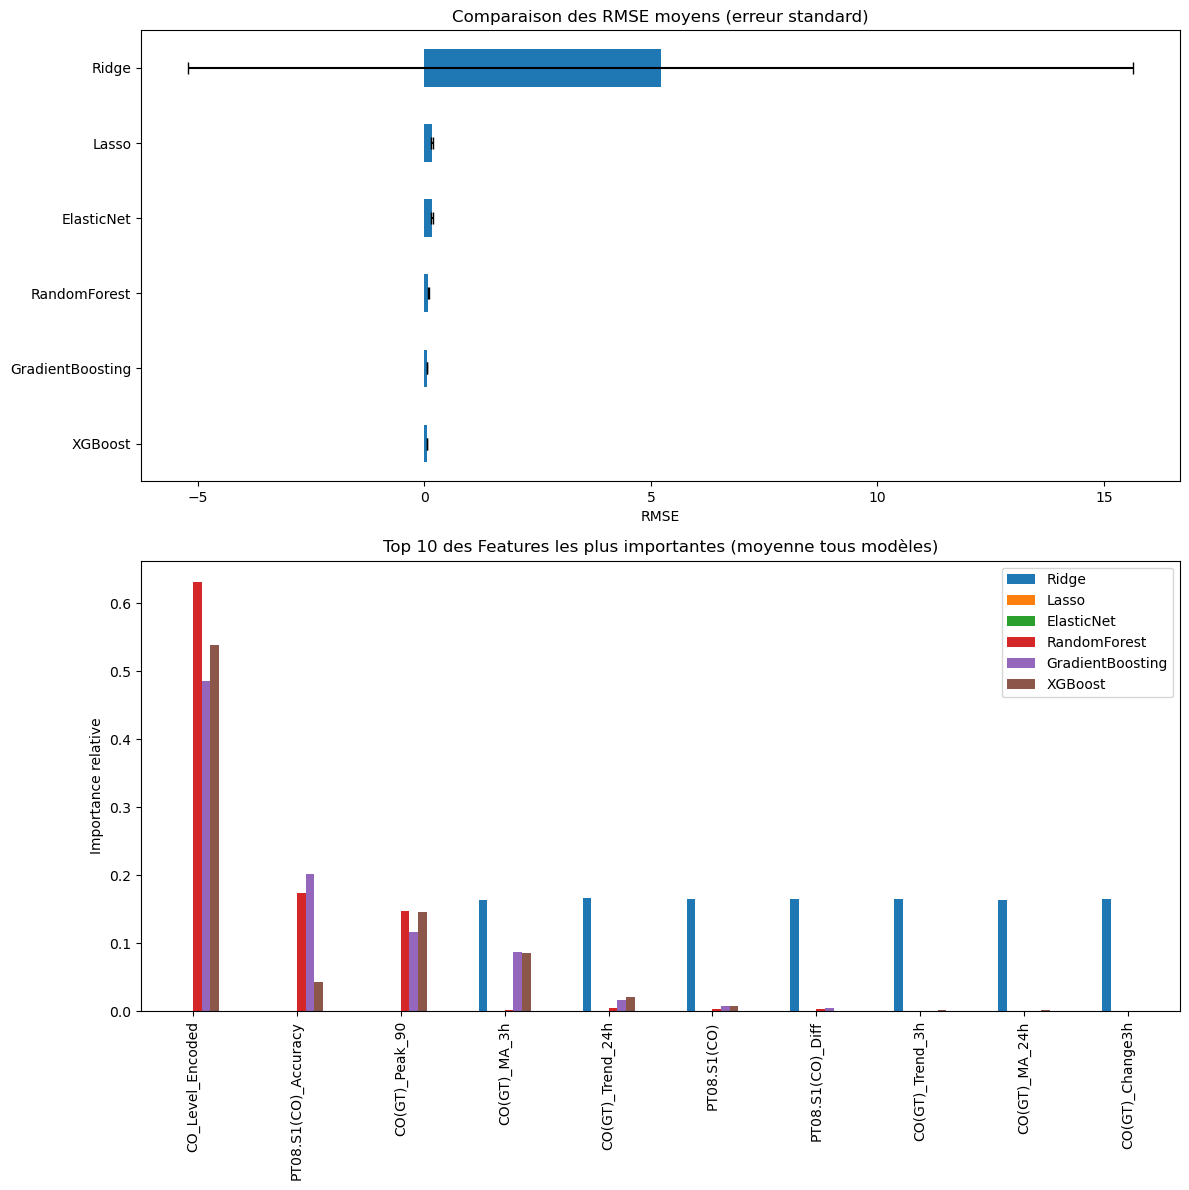

In [40]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import cross_val_score
import numpy as np

# 1. Ajout des modèles d'ensemble
models.update({
    'RandomForest': RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42),
    'GradientBoosting': GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3),
    'XGBoost': XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=3)
})

# 2. Pipeline d'évaluation
results = {}
feature_importances = pd.DataFrame(index=X.columns)

for name, model in models.items():
    # Entraînement et validation croisée
    scores = cross_val_score(model, X, y, cv=5, scoring='neg_mean_squared_error')
    rmse_scores = np.sqrt(-scores)
    
    # Stockage des résultats
    model.fit(X, y)  # Full fit pour feature importance
    results[name] = {
        'RMSE_mean': rmse_scores.mean(),
        'RMSE_std': rmse_scores.std()
    }
    
    # Récupération des importances selon le type de modèle
    if hasattr(model, 'coef_'):
        feature_importances[name] = np.abs(model.coef_)
    elif hasattr(model, 'feature_importances_'):
        feature_importances[name] = model.feature_importances_

# 3. Affichage des performances
results_df = pd.DataFrame(results).T.sort_values('RMSE_mean')
print("\nComparaison des modèles:")
print(results_df)

# 4. Visualisation comparative
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 12))

# Graphique des performances
results_df['RMSE_mean'].plot(kind='barh', ax=ax1, xerr=results_df['RMSE_std'], capsize=4)
ax1.set_title('Comparaison des RMSE moyens (erreur standard)')
ax1.set_xlabel('RMSE')

# Graphique des importances (top 10 features)
top_features = feature_importances.mean(axis=1).sort_values(ascending=False).head(10)
feature_importances.loc[top_features.index].plot(kind='bar', ax=ax2)
ax2.set_title('Top 10 des Features les plus importantes (moyenne tous modèles)')
ax2.set_ylabel('Importance relative')

plt.tight_layout()
plt.show()

c:\Users\0000\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.344e+00, tolerance: 3.468e-01
  model = cd_fast.enet_coordinate_descent(


Comparaison détaillée des modèles :


,MAE,RMSE,R2,Explained Variance,MAPE
Model,,,,,
Ridge,0.000481,0.000646,0.999999,0.999999,0.000418
Lasso,0.105853,0.147664,0.965572,0.965574,0.103168
ElasticNet,0.103378,0.144315,0.967115,0.967118,0.100111


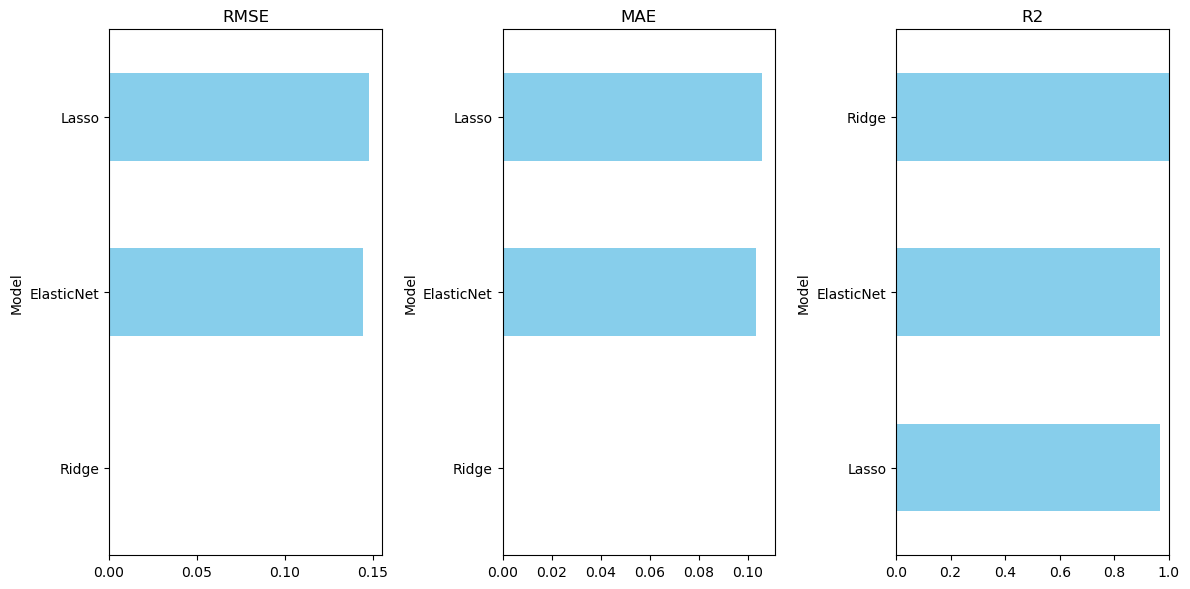

In [44]:
from sklearn.metrics import (
    mean_absolute_error, 
    mean_squared_error, 
    r2_score,
    explained_variance_score,
    mean_absolute_percentage_error
)
from sklearn.model_selection import train_test_split
import numpy as np

# 1. Split des données
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Dictionnaire des métriques à calculer
metrics = {
    'MAE': mean_absolute_error,
    'RMSE': lambda y, y_pred: np.sqrt(mean_squared_error(y, y_pred)),
    'R2': r2_score,
    'Explained Variance': explained_variance_score,
    'MAPE': mean_absolute_percentage_error
}

# 3. Entraînement et évaluation
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    # Calcul de toutes les métriques
    model_metrics = {'Model': name}
    for metric_name, metric_func in metrics.items():
        try:
            model_metrics[metric_name] = metric_func(y_test, y_pred)
        except Exception as e:
            model_metrics[metric_name] = f"Error: {str(e)}"
    
    results.append(model_metrics)

# 4. DataFrame des résultats
results_df = pd.DataFrame(results).set_index('Model')
print("Comparaison détaillée des modèles :")
display(results_df.style.background_gradient(cmap='Blues', subset=['R2', 'Explained Variance'])\
                       .background_gradient(cmap='Reds_r', subset=['MAE', 'RMSE', 'MAPE']))

# 5. Visualisation comparative
plt.figure(figsize=(12, 6))
metrics_to_plot = ['RMSE', 'MAE', 'R2']
for i, metric in enumerate(metrics_to_plot, 1):
    plt.subplot(1, 3, i)
    results_df[metric].sort_values().plot(kind='barh', color='skyblue')
    plt.title(metric)
    if metric == 'R2':
        plt.xlim(0, 1)  # R2 est entre 0 et 1
plt.tight_layout()
plt.show()